In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import torch
from models.StateTransitionNN import StateTransitionSurrogate

# ---------------- Load data ----------------
df = pd.read_csv("../data/raw/h2o2_trajectories.csv")
species_cols = [c.replace("Y_", "") for c in df.columns if c.startswith("Y_")]

# ---------------- Build (t, t+dt) pairs WITHIN each trajectory ----------------
def build_pairs(d):
    rows = []
    for traj_id, g in d.groupby("traj_idx"):
        g = g.sort_values("t").reset_index(drop=True)
        for i in range(len(g) - 1):
            rows.append({
                "T": g.loc[i, "T"], "T_next": g.loc[i + 1, "T"],
                "dt": g.loc[i + 1, "t"] - g.loc[i, "t"],
                **{f"Y_{s}": g.loc[i, f"Y_{s}"] for s in species_cols},
                **{f"Y_{s}_next": g.loc[i + 1, f"Y_{s}"] for s in species_cols},
            })
    return pd.DataFrame(rows)

# ---------------- Split by TRAJECTORY first, then build pairs ----------------
traj_ids = df["traj_idx"].unique()
rng = np.random.default_rng(0)
rng.shuffle(traj_ids)
n_val = int(0.2 * len(traj_ids))
val_ids, train_ids = set(traj_ids[:n_val]), set(traj_ids[n_val:])

train_pairs = build_pairs(df[df["traj_idx"].isin(train_ids)])
val_pairs = build_pairs(df[df["traj_idx"].isin(val_ids)])

def to_tensors(d):
    T = torch.tensor(d["T"].to_numpy(), dtype=torch.float32)
    T_next = torch.tensor(d["T_next"].to_numpy(), dtype=torch.float32)
    dt = torch.tensor(d["dt"].to_numpy(), dtype=torch.float32)
    Y = torch.tensor(d[[f"Y_{s}" for s in species_cols]].to_numpy(), dtype=torch.float32)
    Y_next = torch.tensor(d[[f"Y_{s}_next" for s in species_cols]].to_numpy(), dtype=torch.float32)
    return T, Y, dt, T_next, Y_next

T_tr, Y_tr, dt_tr, T_next_tr, Y_next_tr = to_tensors(train_pairs)
T_va, Y_va, dt_va, T_next_va, Y_next_va = to_tensors(val_pairs)

# ---------------- Model + fit normalization stats on TRAIN only ----------------
model = StateTransitionSurrogate(n_species=len(species_cols))

Y_MIN = model.Y_MIN
logY_all = torch.log(torch.clamp(torch.cat([Y_tr, Y_next_tr], dim=0), min=Y_MIN))
logdt_all = torch.log(torch.clamp(dt_tr, min=1e-12))

model.set_norm_stats(
    logY_mean=logY_all.mean(dim=0), logY_std=logY_all.std(dim=0),
    T_mean=torch.cat([T_tr, T_next_tr]).mean(), T_std=torch.cat([T_tr, T_next_tr]).std(),
    logdt_mean=logdt_all.mean(), logdt_std=logdt_all.std(),
)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)

# ---------------- Train ----------------
n_epochs = 200
batch_size = 512
n_train = T_tr.shape[0]
LAMBDA_MOLE = 1.0   # weight for the mole/mass-fraction-sum-to-1 soft constraint

train_losses, val_losses, val_epochs = [], [], []

for epoch in range(n_epochs):
    perm = torch.randperm(n_train)
    total_loss = 0.0
    for i in range(0, n_train, batch_size):
        idx = perm[i:i + batch_size]

        T_next_pred, Y_next_pred, info = model(T_tr[idx], Y_tr[idx], dt_tr[idx])

        # data loss: MSE in NORMALIZED space (matches CRK-PINN's approach --
        # keeps loss scale comparable across species regardless of magnitude)
        Tn_true = model.normalize_T(T_next_tr[idx])
        Yn_true = model.normalize_Y(Y_next_tr[idx])
        data_loss = torch.nn.functional.mse_loss(info["Tn_next"], Tn_true) \
                  + torch.nn.functional.mse_loss(info["Yn_next"], Yn_true)

        # physics soft constraint: predicted mass fractions should sum to 1
        mole_loss = ((Y_next_pred.sum(dim=-1) - 1.0) ** 2).mean()

        loss = data_loss + LAMBDA_MOLE * mole_loss

        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(idx)

    train_losses.append(total_loss / n_train)

    if epoch % 10 == 0:
        with torch.no_grad():
            T_next_pred_v, Y_next_pred_v, info_v = model(T_va, Y_va, dt_va)
            Tn_true_v = model.normalize_T(T_next_va)
            Yn_true_v = model.normalize_Y(Y_next_va)
            val_loss = torch.nn.functional.mse_loss(info_v["Tn_next"], Tn_true_v) \
                     + torch.nn.functional.mse_loss(info_v["Yn_next"], Yn_true_v)
        val_losses.append(val_loss.item())
        val_epochs.append(epoch)
        print(f"epoch {epoch:4d}  train {total_loss/n_train:.4f}  val {val_loss.item():.4f}")

epoch    0  train 0.4513  val 0.1927
epoch   10  train 0.0171  val 0.0102
epoch   20  train 0.0127  val 0.0085
epoch   30  train 0.1704  val 0.0896
epoch   40  train 0.0116  val 0.0073
epoch   50  train 0.0094  val 0.0062
epoch   60  train 0.0085  val 0.0053
epoch   70  train 0.0083  val 0.0051
epoch   80  train 0.2456  val 0.2129
epoch   90  train 0.0081  val 0.0053
epoch  100  train 0.0073  val 0.0049
epoch  110  train 0.0069  val 0.0045
epoch  120  train 0.0069  val 0.0040
epoch  130  train 0.0068  val 0.0044
epoch  140  train 0.0069  val 0.0041
epoch  150  train 0.0054  val 0.0036
epoch  160  train 0.0054  val 0.0029
epoch  170  train 0.0048  val 0.0031
epoch  180  train 0.0043  val 0.0035
epoch  190  train 0.0035  val 0.0027


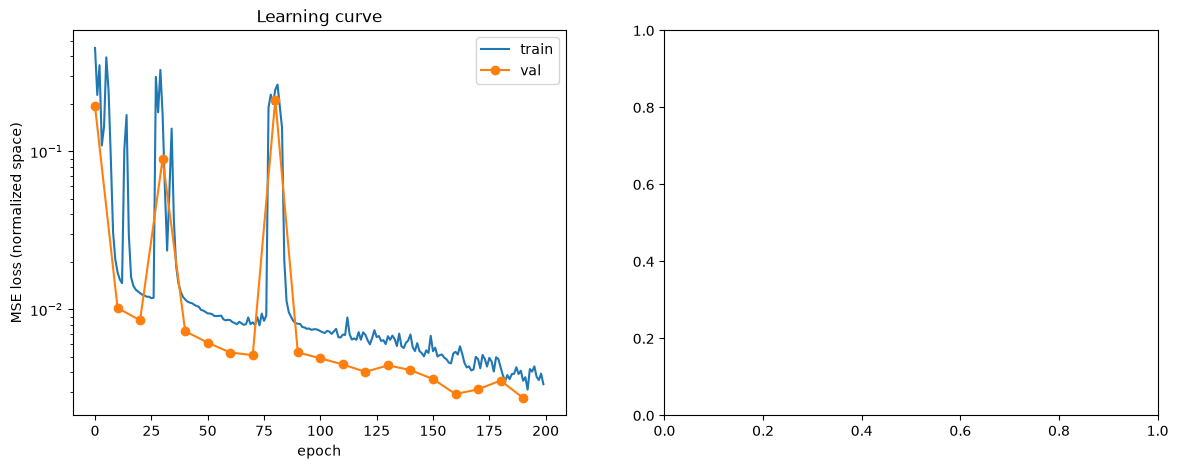

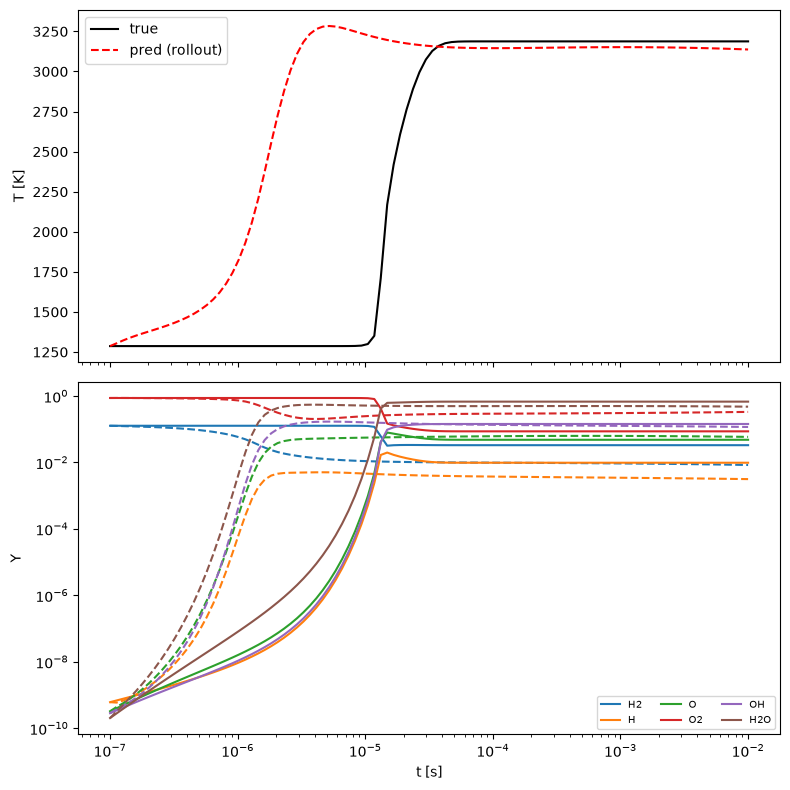

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Learning curve ----
axes[0].plot(train_losses, label="train")
axes[0].plot(val_epochs, val_losses, label="val", marker="o")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE loss (normalized space)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].set_title("Learning curve")

# ---- Rollout on one held-out trajectory ----
traj_id = list(val_ids)[0]
traj = df[df["traj_idx"] == traj_id].sort_values("t").reset_index(drop=True)

T0 = torch.tensor([traj.loc[0, "T"]], dtype=torch.float32)
Y0 = torch.tensor([[traj.loc[0, f"Y_{s}"] for s in species_cols]], dtype=torch.float32)
t_arr = traj["t"].to_numpy()

T_rollout = [T0.item()]
Y_rollout = [Y0.numpy()[0]]

T_cur, Y_cur = T0, Y0
with torch.no_grad():
    for i in range(len(t_arr) - 1):
        dt = torch.tensor([t_arr[i + 1] - t_arr[i]], dtype=torch.float32)
        T_cur, Y_cur, _ = model(T_cur, Y_cur, dt)
        T_rollout.append(T_cur.item())
        Y_rollout.append(Y_cur.numpy()[0])

T_rollout = np.array(T_rollout)
Y_rollout = np.array(Y_rollout)
Y_true = traj[[f"Y_{s}" for s in species_cols]].to_numpy()

fig2, axes2 = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
axes2[0].plot(t_arr, traj["T"], label="true", color="black")
axes2[0].plot(t_arr, T_rollout, label="pred (rollout)", color="red", linestyle="--")
axes2[0].set_ylabel("T [K]")
axes2[0].set_xscale("log")
axes2[0].legend()

n_show = min(6, len(species_cols))
for i in range(n_show):
    axes2[1].plot(t_arr, Y_true[:, i], color=f"C{i}", label=species_cols[i])
    axes2[1].plot(t_arr, Y_rollout[:, i], color=f"C{i}", linestyle="--")
axes2[1].set_xlabel("t [s]")
axes2[1].set_ylabel("Y")
axes2[1].set_yscale("log")
axes2[1].set_xscale("log")
axes2[1].legend(fontsize=7, ncol=3)

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn

R = 8.314462618  # J/(mol*K)


class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.linear = nn.Linear(dim, dim)
        self.act = nn.SiLU()

    def forward(self, x):
        return x + self.act(self.linear(x))


class ArrheniusStateSurrogate(nn.Module):
    """
    Hybrid of ArrheniusNN and StateTransitionSurrogate.

    Species update: keeps the ORIGINAL Arrhenius structure -- the network
    predicts A, b, Ea, and stoichiometric coefficients nu (with mass
    conservation structurally guaranteed via the free/dependent species
    split, exactly as in ArrheniusNN), giving a physically-structured wdot.
    One explicit Euler step then advances the species state:

        Y_next = Y_t + (wdot * mw / rho_tot) * dt

    Because sum_i(wdot_i * mw_i) = 0 is guaranteed by construction, and
    Y_t sums to 1 in the data, Y_next sums to exactly 1 as well -- the
    mass-fraction-sum-to-1 constraint falls out for free, no soft loss
    term needed for it (unlike StateTransitionSurrogate).

    Temperature update: predicted directly by a separate output head, NOT
    derived from wdot via energy conservation. A fully physical Tdot would
    require evaluating NASA polynomial enthalpies/cv inside the model
    (what Cantera does in generate_data_simple.py's compute step) -- left
    out here for simplicity. This is a real approximation: T_next is
    learned freely, only the species update is physically structured.
    Worth revisiting if the T-prediction turns out to be the bottleneck.

    Loss should be computed in NORMALIZED STATE SPACE (Z-scored log-Y,
    Z-scored T) against the true next state, exactly like
    StateTransitionSurrogate -- NOT in raw log|wdot| space. This is what
    fixes the original dynamic-range/data-imbalance problem, while keeping
    hard mass conservation.
    """

    Y_MIN = 1e-10

    def __init__(self, n_species, molecular_weights, hidden=512, n_layers=8, eps=1e-30):
        super().__init__()
        self.n_species = n_species
        self.register_buffer("mw", torch.tensor(molecular_weights, dtype=torch.float32))
        self.eps = eps

        self.dependent_idx = int(torch.argmax(self.mw).item())
        self.free_idx = [i for i in range(n_species) if i != self.dependent_idx]

        # input: T, log-Y (n_species), dt  -->  hidden
        in_dim = 1 + n_species + 1
        self.input_layer = nn.Linear(in_dim, hidden)
        self.blocks = nn.ModuleList([ResidualBlock(hidden) for _ in range(n_layers - 2)])

        # output: A, b, Ea, nu_free (n_species - 1), dT_raw (1)
        out_dim = 3 + (n_species - 1) + 1
        self.output_layer = nn.Linear(hidden, out_dim)

        EA_INIT = 40000.0
        with torch.no_grad():
            last_layer = self.output_layer
            last_layer.weight[1, :] *= 0.1
            last_layer.bias[1] *= 0.1
            last_layer.weight[2, :] *= 0.1
            last_layer.bias[2] = EA_INIT
            last_layer.bias[3:3 + n_species - 1] = torch.zeros(n_species - 1)
            last_layer.weight[3:3 + n_species - 1, :] *= 0.3
            # dT output: start near zero so the model defaults to "no change"
            # (same reasoning as the residual-prediction fix for the drift problem)
            last_layer.weight[-1, :] *= 0.01
            last_layer.bias[-1] *= 0.01

        self.b_max = 6.0
        self.nu_max = 4.0

        # normalization stats -- fit on TRAIN split only via set_norm_stats
        self.register_buffer("logY_mean", torch.zeros(n_species))
        self.register_buffer("logY_std", torch.ones(n_species))
        self.register_buffer("T_mean", torch.tensor(0.0))
        self.register_buffer("T_std", torch.tensor(1.0))
        self.register_buffer("logdt_mean", torch.tensor(0.0))
        self.register_buffer("logdt_std", torch.tensor(1.0))
        self.register_buffer("dT_std", torch.tensor(1.0))  # scale for the raw dT output

    def set_norm_stats(self, logY_mean, logY_std, T_mean, T_std, logdt_mean, logdt_std, dT_std):
        self.logY_mean.copy_(torch.as_tensor(logY_mean))
        self.logY_std.copy_(torch.as_tensor(logY_std).clamp_min(1e-8))
        self.T_mean.copy_(torch.as_tensor(T_mean))
        self.T_std.copy_(torch.as_tensor(T_std).clamp_min(1e-8))
        self.logdt_mean.copy_(torch.as_tensor(logdt_mean))
        self.logdt_std.copy_(torch.as_tensor(logdt_std).clamp_min(1e-8))
        self.dT_std.copy_(torch.as_tensor(dT_std).clamp_min(1e-8))

    def normalize_Y(self, Y):
        logY = torch.log(torch.clamp(Y, min=self.Y_MIN))
        return (logY - self.logY_mean) / self.logY_std

    def normalize_T(self, T):
        return (T - self.T_mean) / self.T_std

    def denormalize_T(self, Tn):
        return Tn * self.T_std + self.T_mean

    def normalize_dt(self, dt):
        logdt = torch.log(torch.clamp(dt, min=1e-12))
        return (logdt - self.logdt_mean) / self.logdt_std

    def _assemble_nu(self, nu_free):
        batch = nu_free.shape[0]
        nu = torch.zeros(batch, self.n_species, device=nu_free.device, dtype=nu_free.dtype)
        free_idx = torch.tensor(self.free_idx, device=nu_free.device)
        nu[:, free_idx] = nu_free

        mw_free = self.mw[free_idx]
        mw_dep = self.mw[self.dependent_idx]
        nu_dep = -(nu_free * mw_free.unsqueeze(0)).sum(dim=-1) / mw_dep
        nu[:, self.dependent_idx] = nu_dep
        return nu

    def forward(self, T, Y, rho_tot, dt):
        """
        T: (batch,) current temperature
        Y: (batch, n_species) current mass fractions
        rho_tot: (batch,) current mixture density (kg/m3)
        dt: (batch,) time step

        Returns: T_next, Y_next (physical units), plus info dict with
        intermediate quantities (wdot, nu, A, b, Ea) for inspection.
        """
        Tn = self.normalize_T(T)
        logYn = self.normalize_Y(Y)
        dtn = self.normalize_dt(dt)

        x = torch.cat([Tn.unsqueeze(-1), logYn, dtn.unsqueeze(-1)], dim=-1)

        h = nn.functional.silu(self.input_layer(x))
        for block in self.blocks:
            h = block(h)
        out = self.output_layer(h)

        A = nn.functional.softplus(out[:, 0]) + 1e-12
        b = self.b_max * torch.tanh(out[:, 1])
        Ea = nn.functional.softplus(out[:, 2])
        nu_free = self.nu_max * torch.tanh(out[:, 3:3 + self.n_species - 1] / self.nu_max)
        dT_raw = out[:, -1]

        nu = self._assemble_nu(nu_free)

        log_k = torch.log(A) + b * torch.log(300.0 / T) - Ea / (R * T)  # T_ref fixed at 300K here

        rho_species = Y * rho_tot.unsqueeze(-1)
        C = rho_species / self.mw
        order = torch.relu(-nu)
        log_C = torch.log(torch.clamp(C, min=1e-20))

        log_rate_term = (order * log_C).sum(dim=-1)
        log_q = log_k + log_rate_term

        log_nu_mag = torch.log(torch.abs(nu) + self.eps)
        log_wdot_mag = log_nu_mag + log_q.unsqueeze(-1)
        wdot_sign = torch.sign(nu)
        wdot = wdot_sign * torch.exp(torch.clamp(log_wdot_mag, max=80.0))  # kmol/m3/s

        Ydot = wdot * self.mw.unsqueeze(0) / rho_tot.unsqueeze(-1)

        # ---- Euler step ----
        Y_next = Y + Ydot * dt.unsqueeze(-1)
        Y_next = torch.clamp(Y_next, min=0.0)  # mass fractions can't go negative

        T_next = T + dT_raw * self.dT_std * dt  # dT_raw scaled + multiplied by dt so units work out

        return T_next, Y_next, {
            "wdot": wdot, "Ydot": Ydot, "nu": nu, "A": A, "b": b, "Ea": Ea,
        }